In [1]:
# Imports and data directory
from pathlib import Path
import os, sys
import numpy as np
import pandas as pd
from IPython.display import display

repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Reproduce").is_dir())
sys.path.insert(0, str(repo / "Reproduce"))
from _shared.paper_plots import *
from _shared.workflow import align_partition
from _shared.io import load_features
DATA_ROOT = Path(os.environ.get("MELON_PUBLISHED_DATA", repo / "Published_Data_non_NASH"))
DATA = DATA_ROOT / "04_Human_tonsil"
assert DATA.is_dir(), "Place Published_Data_non_NASH beside Reproduce, or set MELON_PUBLISHED_DATA."

RUN_TRAINING = False  # True: train from preprocessed features. False: use supplied results.

In [2]:
# Preprocessed inputs
modalities = ['RNA', 'Protein', 'Image']
FEATURES = DATA / "02_model_inputs/MELON/features.npz"
if RUN_TRAINING:
    # Supply normalized, aligned matrices with barcodes and coords in this NPZ.
    barcodes, xy, features = load_features(FEATURES, modalities)
    coords = pd.DataFrame(xy, index=barcodes, columns=["x", "y"])
else:
    coords = read_indexed(DATA / "01_source_data/coords.csv")[["x", "y"]]

In [3]:
# Parameters
config = {
    'epochs': 30,
    'batch_size': 4096,
    'embed_dim': 128,
    'training_seed': 42,
    'learning_rate': 0.001,
    'weight_decay': 1e-05,
    'temperature': 0.1,
    'training_spatial_k': 6,
    'export_spatial_k': None,
    'augment_p': 0.8,
    'augmentations': ['gaussian_noise', 'feature_dropout', 'neighbor_mix'],
    'shuffle_batches': False,
    'historical_five_modal': False,
    'clustering_seed': 2025,
    'target_clusters': 10,
    'kmeans_n_init': 20,
}

In [4]:
# Spatial graph and augmented views
if RUN_TRAINING:
    import torch
    from torch import nn
    from types import MethodType
    import pytorch_lightning as pl
    from _shared.publication_model.data import DualAugDataModule, SpatialOmicsAugmentations
    from _shared.publication_model.model import SpotTokenAdapter
    from _shared.publication_model.models.mmfusion import MMFusion
    from _shared.publication_model.pl_modules.melon import MELONModel
    from _shared.publication_model.utils import build_knn_mask
    from _shared.engine import PaperAugmentations, HistoricalLoss, export_embedding

    pl.seed_everything(config["training_seed"], workers=True)
    tensors = [torch.tensor(x, dtype=torch.float32) for x in features]
    xy = torch.as_tensor(coords.to_numpy(), dtype=torch.float32)
    mask, weights = build_knn_mask(xy, k=config["training_spatial_k"],
                                   include_self=True, return_weights=True)
    augmentation = SpatialOmicsAugmentations if config["historical_five_modal"] else PaperAugmentations
    aug = dict(augmentations=config["augmentations"], p=config["augment_p"])
    data = DualAugDataModule(
        mods_raw=tensors, coords=xy, neighbor_mask=mask, neighbor_weight=weights,
        augmentA=augmentation(**aug), augmentB=augmentation(**aug),
        batch_size=config["batch_size"], shuffle=config["shuffle_batches"],
        spot_tokenization=True,
    )

In [5]:
# MELON model
if RUN_TRAINING:
    dim = config["embed_dim"]
    encoder = MMFusion(
        encoders=[nn.Sequential(nn.Linear(x.shape[1], dim), nn.ReLU(), nn.Linear(dim, dim))
                  for x in tensors],
        input_adapters=[SpotTokenAdapter() for _ in tensors],
        embed_dim=dim, fusion="concat", pool="tokens", n_heads=8, n_layers=1,
    )
    model = MELONModel(
        encoder=encoder, projection=MELONModel._build_mlp(dim, 256, dim),
        optim_kwargs={"lr": config["learning_rate"], "weight_decay": config["weight_decay"]},
        loss_kwargs={"temperature": config["temperature"]},
        neighborhood_cfg={"hidden_dim": 64, "heads": 8, "dropout": 0.1,
                          "k_neighbors": config["training_spatial_k"], "include_self": True},
    )
    if config["historical_five_modal"]:
        model.loss = HistoricalLoss(temperature=config["temperature"])
    else:
        def configure_optimizers(self):
            return torch.optim.Adam(self.parameters(), **self.optim_kwargs, betas=(0.9, 0.999))
        model.configure_optimizers = MethodType(configure_optimizers, model)

In [6]:
# Train and embed
if RUN_TRAINING:
    trainer = pl.Trainer(max_epochs=config["epochs"], accelerator="cpu", devices=1,
                         logger=False, enable_checkpointing=False, deterministic=True)
    trainer.fit(model, datamodule=data)
    embedding = pd.DataFrame(
        export_embedding(model, tensors, xy, spatial_k=config["export_spatial_k"]),
        index=coords.index,
    )
else:
    embedding = read_indexed(DATA / "03_embeddings/MELON.csv")
    embedding = align_embedding(embedding, coords)
display({"spots": len(embedding), "embedding_dimensions": embedding.shape[1]})

{'spots': 4194, 'embedding_dimensions': 128}

In [7]:
# Spatial clustering
if RUN_TRAINING:
    from sklearn.cluster import KMeans
    labels = KMeans(n_clusters=config["target_clusters"], n_init=config["kmeans_n_init"],
                    random_state=config["clustering_seed"]).fit_predict(embedding)
    domains = pd.Series(labels, index=embedding.index, name="MELON")
else:
    domains = align_partition(DATA / "04_clusters/final_clusters.csv", embedding)
display({"spatial_domains": domains.nunique()})

{'spatial_domains': 10}

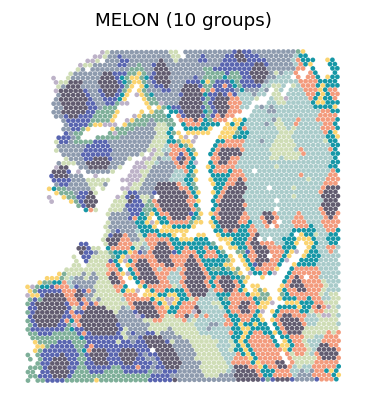

In [8]:
# Spatial plot
plot_data = coords.loc[embedding.index].copy()
plot_data["MELON"] = domains
colors = None if RUN_TRAINING else tonsil_colors(DATA)
show(spatial_panels(plot_data, ["MELON"], colors=colors, ncols=1))